<a href="https://colab.research.google.com/github/olopez27CL/Lab01_EDA_Lopez_Omar/blob/main/Lab_Clustering_Kmeans_Jerarquico/Actividad_2_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ejercico 1: Clustering K-means

In [1]:
!pip -q install kagglehub

import kagglehub
import os
import pandas as pd

carpeta = kagglehub.dataset_download(
    "vjchoudhary7/customer-segmentation-tutorial-in-python"
)

print(os.listdir(carpeta))

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.
['Mall_Customers.csv']


In [2]:
archivo = os.path.join(carpeta, "Mall_Customers.csv")
datos = pd.read_csv(archivo)

datos.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


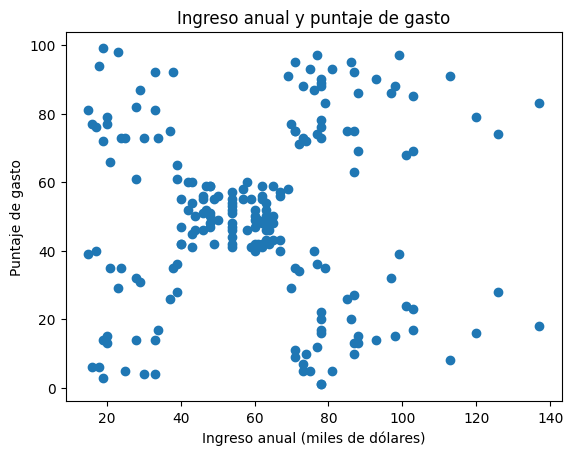

In [3]:
import matplotlib.pyplot as plt

plt.scatter(datos["Annual Income (k$)"], datos["Spending Score (1-100)"])
plt.xlabel("Ingreso anual (miles de dólares)")
plt.ylabel("Puntaje de gasto")
plt.title("Ingreso anual y puntaje de gasto")
plt.show()

Al observar el gráfico, estimo que podrían existir alrededor de cinco grupos de clientes. Distingo clientes con ingresos bajos y puntajes de gasto bajos o altos, un grupo concentrado en valores medios y clientes con ingresos altos que también parecen separarse según su puntaje de gasto. Esta es una hipótesis inicial basada en la distribución de los puntos.

In [4]:
print("Dimensiones de la tabla (filas, columnas):")
print(datos.shape)

print("\nTipos de datos y columnas:")
datos.info()

print("\nValores vacíos por columna:")
print(datos.isna().sum())

print("\nResumen de las columnas numéricas:")
print(datos.describe())

print("\nCantidad de clientes por género:")
print(datos["Gender"].value_counts())

Dimensiones de la tabla (filas, columnas):
(200, 5)

Tipos de datos y columnas:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Valores vacíos por columna:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Resumen de las columnas numéricas:
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000       

La tabla contiene 200 clientes y no presenta valores vacíos. Cada fila representa a un cliente. No usaré CustomerID para formar los grupos porque solo es un identificador. Tampoco incluiré Gender en la distancia: al convertirlo en 0 y 1, la diferencia entre categorías influiría en el cálculo como si fuera una medida numérica. Para comenzar usaré el ingreso anual, que va de 15 a 137, y el puntaje de gasto, que va de 1 a 99.

In [5]:
variables = datos[["Annual Income (k$)", "Spending Score (1-100)"]]

print("Valores mínimos:")
print(variables.min())

print("\nValores máximos:")
print(variables.max())

Valores mínimos:
Annual Income (k$)        15
Spending Score (1-100)     1
dtype: int64

Valores máximos:
Annual Income (k$)        137
Spending Score (1-100)     99
dtype: int64


In [6]:
from sklearn.preprocessing import StandardScaler

escalador = StandardScaler()
valores_estandarizados = escalador.fit_transform(variables)

variables_estandarizadas = pd.DataFrame(
    valores_estandarizados,
    columns=variables.columns
)

variables_estandarizadas.head()

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inercias = []
siluetas = []

for k in range(2, 11):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    grupos = modelo.fit_predict(variables_estandarizadas)

    inercias.append(modelo.inertia_)
    siluetas.append(silhouette_score(variables_estandarizadas, grupos))

    print("Grupos:", k)
    print("Inercia:", round(modelo.inertia_, 2))
    print("Silueta:", round(siluetas[-1], 3))
    print()

Grupos: 2
Inercia: 269.69
Silueta: 0.321

Grupos: 3
Inercia: 157.7
Silueta: 0.467

Grupos: 4
Inercia: 108.92
Silueta: 0.494

Grupos: 5
Inercia: 65.57
Silueta: 0.555

Grupos: 6
Inercia: 55.06
Silueta: 0.54

Grupos: 7
Inercia: 44.86
Silueta: 0.528

Grupos: 8
Inercia: 37.23
Silueta: 0.455

Grupos: 9
Inercia: 32.39
Silueta: 0.457

Grupos: 10
Inercia: 29.98
Silueta: 0.443



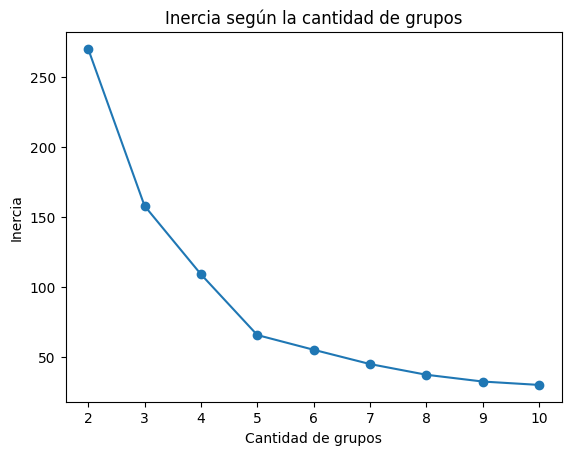

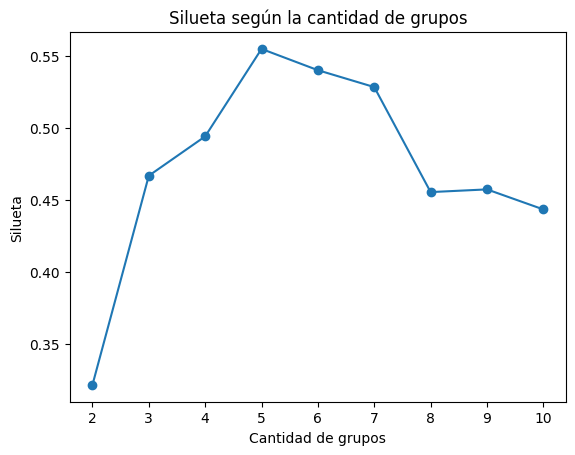

In [8]:
k_valores = list(range(2, 11))

plt.plot(k_valores, inercias, marker="o")
plt.xlabel("Cantidad de grupos")
plt.ylabel("Inercia")
plt.title("Inercia según la cantidad de grupos")
plt.show()

plt.plot(k_valores, siluetas, marker="o")
plt.xlabel("Cantidad de grupos")
plt.ylabel("Silueta")
plt.title("Silueta según la cantidad de grupos")
plt.show()

Los gráficos sugieren probar cinco grupos. La silueta obtiene su valor más alto con k = 5, y en la curva de inercia la disminución se hace más lenta después de cinco grupos. Esto también coincide con mi hipótesis inicial. Por ahora tomaré k = 5 como una opción inicial y revisaré su estabilidad y la utilidad de los grupos antes de decidir definitivamente.

In [9]:
from sklearn.metrics import adjusted_rand_score

modelo_base = KMeans(n_clusters=5, random_state=42, n_init=10)
grupos_base = modelo_base.fit_predict(variables_estandarizadas)

for semilla in [1, 7, 21]:
    modelo_prueba = KMeans(n_clusters=5, random_state=semilla, n_init=10)
    grupos_prueba = modelo_prueba.fit_predict(variables_estandarizadas)

    coincidencia = adjusted_rand_score(grupos_base, grupos_prueba)
    print("Semilla:", semilla, "| Coincidencia:", round(coincidencia, 3))

Semilla: 1 | Coincidencia: 1.0
Semilla: 7 | Coincidencia: 1.0
Semilla: 21 | Coincidencia: 1.0


Al repetir K-means con cinco grupos y distintas semillas, el índice de coincidencia fue 1,0 en todos los casos. Esto indica que las asignaciones se mantuvieron iguales en estas pruebas.

In [10]:
modelo_sin_estandarizar = KMeans(n_clusters=5, random_state=42, n_init=10)
grupos_sin_estandarizar = modelo_sin_estandarizar.fit_predict(variables)

print("Tamaño de los grupos con datos estandarizados:")
print(pd.Series(grupos_base).value_counts().sort_index())

print("\nTamaño de los grupos sin estandarizar:")
print(pd.Series(grupos_sin_estandarizar).value_counts().sort_index())

print("\nComparación de las asignaciones:")
print(pd.crosstab(grupos_base, grupos_sin_estandarizar))

Tamaño de los grupos con datos estandarizados:
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Tamaño de los grupos sin estandarizar:
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Comparación de las asignaciones:
col_0   0   1   2   3   4
row_0                    
0      81   0   0   0   0
1       0  39   0   0   0
2       0   0  22   0   0
3       0   0   0  35   0
4       0   0   0   0  23


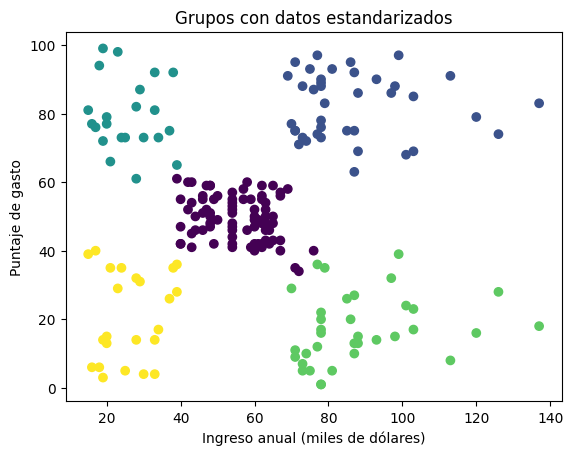

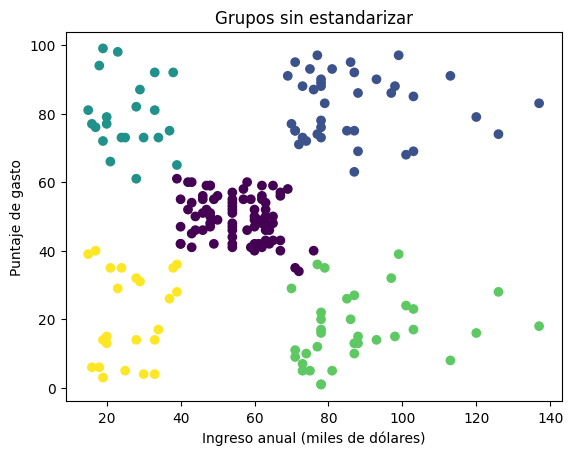

In [11]:
plt.scatter(
    variables["Annual Income (k$)"],
    variables["Spending Score (1-100)"],
    c=grupos_base
)
plt.xlabel("Ingreso anual (miles de dólares)")
plt.ylabel("Puntaje de gasto")
plt.title("Grupos con datos estandarizados")
plt.show()

plt.scatter(
    variables["Annual Income (k$)"],
    variables["Spending Score (1-100)"],
    c=grupos_sin_estandarizar
)
plt.xlabel("Ingreso anual (miles de dólares)")
plt.ylabel("Puntaje de gasto")
plt.title("Grupos sin estandarizar")
plt.show()

Al comparar los resultados con y sin estandarizar, los grupos quedaron iguales. Los tamaños fueron 81, 39, 22, 35 y 23 clientes, y la tabla cruzada mostró las mismas asignaciones. Esto también se observa en los gráficos. Probablemente ocurrió porque el ingreso anual y el puntaje de gasto tienen una dispersión parecida en estos datos, por lo que ninguna variable dominó claramente el cálculo de las distancias. En este caso, estandarizar no cambió el resultado.

In [12]:
datos_con_grupo = datos.copy()
datos_con_grupo["Grupo"] = grupos_base

print("Cantidad de clientes por grupo:")
print(datos_con_grupo["Grupo"].value_counts().sort_index())

perfil = datos_con_grupo.groupby("Grupo").agg({
    "Annual Income (k$)": ["mean", "median"],
    "Spending Score (1-100)": ["mean", "median"]
})

perfil

Cantidad de clientes por grupo:
Grupo
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


Annual Income (k$)        Spending Score (1-100)       
                    mean median                   mean median
Grupo                                                        
0              55.296296   54.0              49.518519   50.0
1              86.538462   79.0              82.128205   83.0
2              25.727273   24.5              79.363636   77.0
3              88.200000   85.0              17.114286   16.0
4              26.304348   25.0              20.913043   17.0

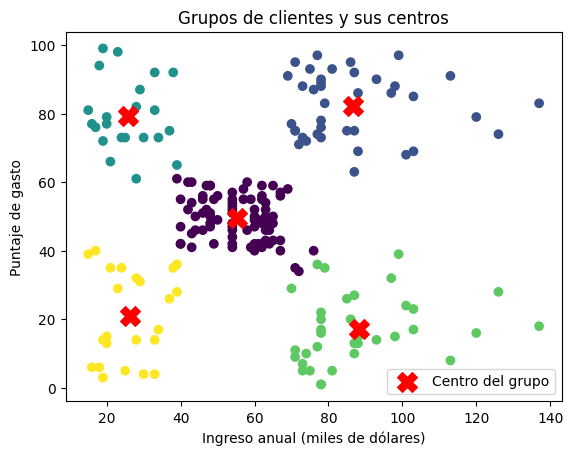

In [13]:
centros = datos_con_grupo.groupby("Grupo")[
    ["Annual Income (k$)", "Spending Score (1-100)"]
].mean()

plt.scatter(
    datos_con_grupo["Annual Income (k$)"],
    datos_con_grupo["Spending Score (1-100)"],
    c=grupos_base
)

plt.scatter(
    centros["Annual Income (k$)"],
    centros["Spending Score (1-100)"],
    marker="X",
    s=200,
    c="red",
    label="Centro del grupo"
)

plt.xlabel("Ingreso anual (miles de dólares)")
plt.ylabel("Puntaje de gasto")
plt.title("Grupos de clientes y sus centros")
plt.legend()
plt.show()

Mi hipótesis inicial de cinco grupos coincidió con el resultado de K-means. En el gráfico se distinguen grupos con distintos niveles de ingreso y puntaje de gasto, y las X rojas muestran el promedio de cada grupo. Me llamó la atención que el grupo de valores medios sea el más numeroso, con 81 clientes. Estos segmentos permiten proponer comunicaciones distintas, aunque los datos solo muestran ingreso y puntaje de gasto y no explican por qué compra cada cliente.

## Ejercicio 2: Clustering jerárquico

In [14]:
!pip -q install kagglehub

import kagglehub
import os

carpeta_paises = kagglehub.dataset_download(
    "rohan0301/unsupervised-learning-on-country-data"
)

print(os.listdir(carpeta_paises))

Using Colab cache for faster access to the 'unsupervised-learning-on-country-data' dataset.
['Country-data.csv', 'data-dictionary.csv']


In [15]:
import pandas as pd

archivo_paises = os.path.join(carpeta_paises, "Country-data.csv")
paises = pd.read_csv(archivo_paises)

paises.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [16]:
paises["country"].unique()

array(['Afghanistan', 'Albania', 'Algeria', 'Angola',
       'Antigua and Barbuda', 'Argentina', 'Armenia', 'Australia',
       'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Bangladesh',
       'Barbados', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bhutan',
       'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil',
       'Brunei', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia',
       'Cameroon', 'Canada', 'Cape Verde', 'Central African Republic',
       'Chad', 'Chile', 'China', 'Colombia', 'Comoros',
       'Congo, Dem. Rep.', 'Congo, Rep.', 'Costa Rica', "Cote d'Ivoire",
       'Croatia', 'Cyprus', 'Czech Republic', 'Denmark',
       'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador',
       'Equatorial Guinea', 'Eritrea', 'Estonia', 'Fiji', 'Finland',
       'France', 'Gabon', 'Gambia', 'Georgia', 'Germany', 'Ghana',
       'Greece', 'Grenada', 'Guatemala', 'Guinea', 'Guinea-Bissau',
       'Guyana', 'Haiti', 'Hungary', 'Iceland', 'India', 'Indonesia',
       'Iran

In [17]:
vecinos = paises[paises["country"].isin(["Chile", "Argentina", "Uruguay"])]

otros = paises[~paises["country"].isin(["Chile", "Argentina", "Uruguay"])]
otros = otros.sample(n=27, random_state=42)

muestra_paises = pd.concat([vecinos, otros])
muestra_paises = muestra_paises.reset_index(drop=True)

muestra_paises["country"].tolist()

['Argentina',
 'Chile',
 'Uruguay',
 'South Africa',
 'Panama',
 'Singapore',
 'Georgia',
 'Mali',
 'Cape Verde',
 'United States',
 'Finland',
 'Mongolia',
 'Tanzania',
 'Bosnia and Herzegovina',
 'Lesotho',
 'Belize',
 'Iceland',
 'Burkina Faso',
 'Central African Republic',
 'Slovak Republic',
 'Myanmar',
 'Turkmenistan',
 'Benin',
 'Japan',
 'Bolivia',
 'Barbados',
 'Bahamas',
 'Chad',
 'United Arab Emirates',
 'Mauritius']

In [18]:
print("Cantidad de países:", len(muestra_paises))

print("\nDatos vacíos por columna:")
print(muestra_paises.isnull().sum())

print("\nResumen de las columnas numéricas:")
muestra_paises.describe()

Cantidad de países: 30

Datos vacíos por columna:
country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

Resumen de las columnas numéricas:


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,30.000000,30.000000,30.000000,30.000000,30.00000,30.000000,30.000000,30.000000,30.000000
mean,42.903333,42.436967,7.071333,47.312197,17491.60000,5.521267,70.016667,2.886333,13739.800000
std,47.652749,35.848843,3.248499,32.097253,18246.91455,7.935124,10.214968,1.608296,16560.881832
min,2.600000,0.109000,1.970000,0.065900,888.00000,-1.900000,46.500000,1.150000,446.000000
25%,8.625000,23.050000,4.607500,29.225000,4142.50000,0.946250,62.900000,1.870000,1372.500000
50%,17.650000,35.900000,7.315000,43.400000,10970.00000,3.370000,73.100000,2.390000,5945.000000
75%,63.800000,50.075000,8.902500,57.300000,22025.00000,6.982500,76.775000,3.107500,16450.000000
max,150.000000,200.000000,17.900000,174.000000,72100.00000,39.200000,82.800000,6.590000,48400.000000


In [19]:
archivo_diccionario = os.path.join(carpeta_paises, "data-dictionary.csv")
diccionario = pd.read_csv(archivo_diccionario)

diccionario

,Column Name,Description
0,country,Name of the country
1,child_mort,Death of children under 5 years of age per 100...
2,exports,Exports of goods and services per capita. Give...
3,health,Total health spending per capita. Given as %ag...
4,imports,Imports of goods and services per capita. Give...
5,Income,Net income per person
6,Inflation,The measurement of the annual growth rate of t...
7,life_expec,The average number of years a new born child w...
8,total_fer,The number of children that would be born to e...
9,gdpp,The GDP per capita. Calculated as the Total GD...


Variables y escalas: child_mort mide muertes de menores de cinco años por cada 1.000 nacimientos, exports, health e imports son porcentajes, income es el ingreso neto por persona, inflation representa el crecimiento anual, life_expec mide años de esperanza de vida, total_fer indica la cantidad de hijos por mujer y gdpp es el PIB por persona.
Las magnitudes son distintas. En particular, income y gdpp tienen valores mucho mayores que varias de las otras columnas, por lo que podrían tener más influencia en las distancias si no preparamos los datos.

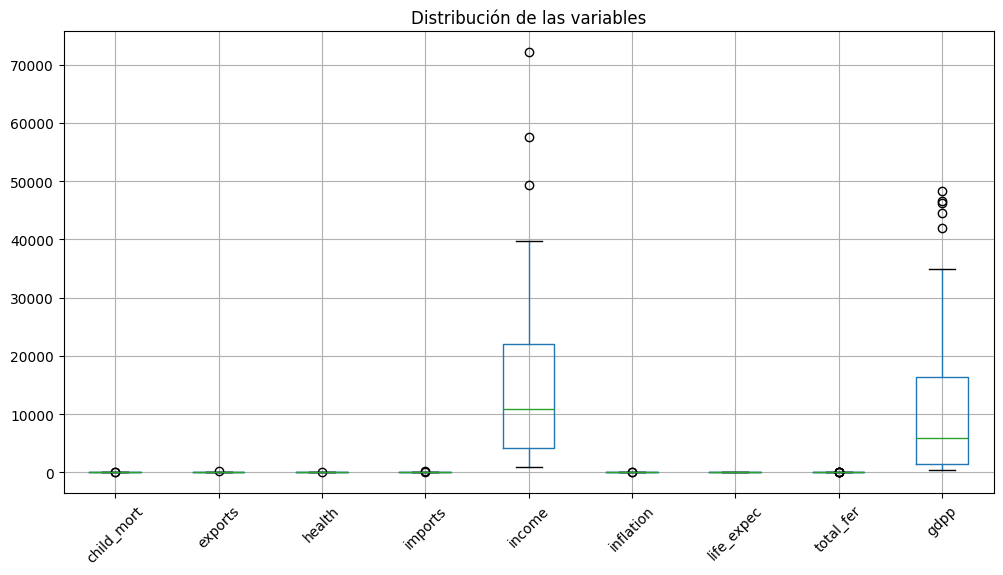

In [20]:
import matplotlib.pyplot as plt

muestra_paises.drop(columns=["country"]).boxplot(figsize=(12, 6), rot=45)
plt.title("Distribución de las variables")
plt.show()

¿Qué espero que ocurra al estandarizar los datos?
Espero que las variables queden en una escala comparable. Así, income y gdpp no tendrán más influencia solo por tener valores numéricos más grandes.

In [21]:
from sklearn.preprocessing import StandardScaler

nombres_paises = muestra_paises["country"]
datos_originales = muestra_paises.drop(columns=["country"])

escalador = StandardScaler()
datos_estandarizados = pd.DataFrame(
    escalador.fit_transform(datos_originales),
    columns=datos_originales.columns
)

datos_estandarizados.head()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,-0.606238,-0.667785,0.322072,-0.992218,0.067357,1.971190,0.575841,-0.326532,-0.211257
1,-0.730032,-0.134396,0.278239,-0.507393,0.106375,0.440764,0.904419,-0.636411,-0.051577
2,-0.689479,-0.457834,0.400347,-0.694352,-0.021828,-0.078350,0.635583,-0.509930,-0.112992
3,0.230443,-0.392579,0.585074,-0.630976,-0.306105,0.106224,-1.564894,-0.187403,-0.396732
4,-0.495250,0.782012,0.322072,0.978770,-0.116587,-0.375719,0.774980,-0.168431,-0.347600


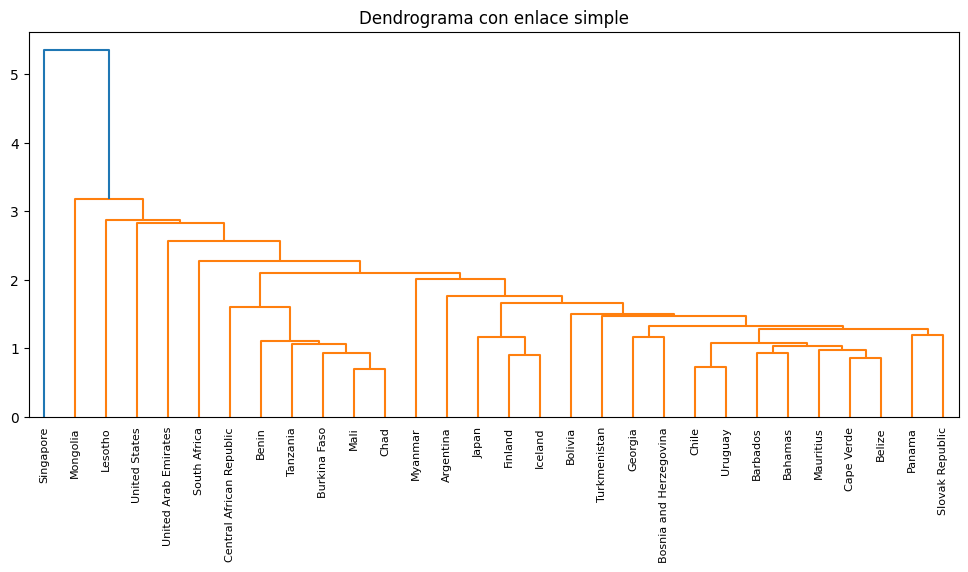

In [22]:
from scipy.cluster.hierarchy import linkage, dendrogram

matriz_simple = linkage(datos_estandarizados, method="single")

plt.figure(figsize=(12, 5))
dendrogram(
    matriz_simple,
    labels=nombres_paises.tolist(),
    leaf_rotation=90,
    leaf_font_size=8
)
plt.title("Dendrograma con enlace simple")
plt.show()

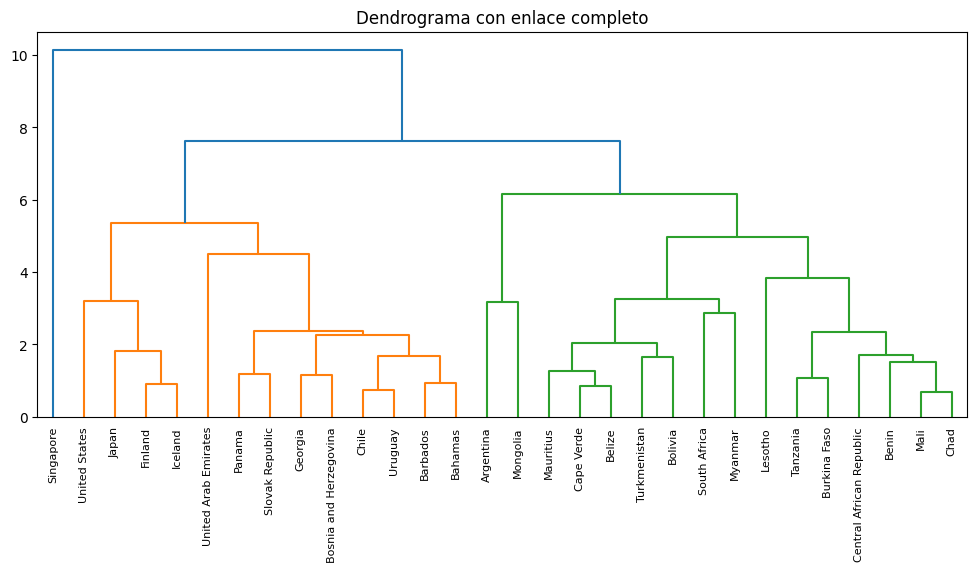

In [23]:
matriz_completa = linkage(datos_estandarizados, method="complete")

plt.figure(figsize=(12, 5))
dendrogram(
    matriz_completa,
    labels=nombres_paises.tolist(),
    leaf_rotation=90,
    leaf_font_size=8
)
plt.title("Dendrograma con enlace completo")
plt.show()

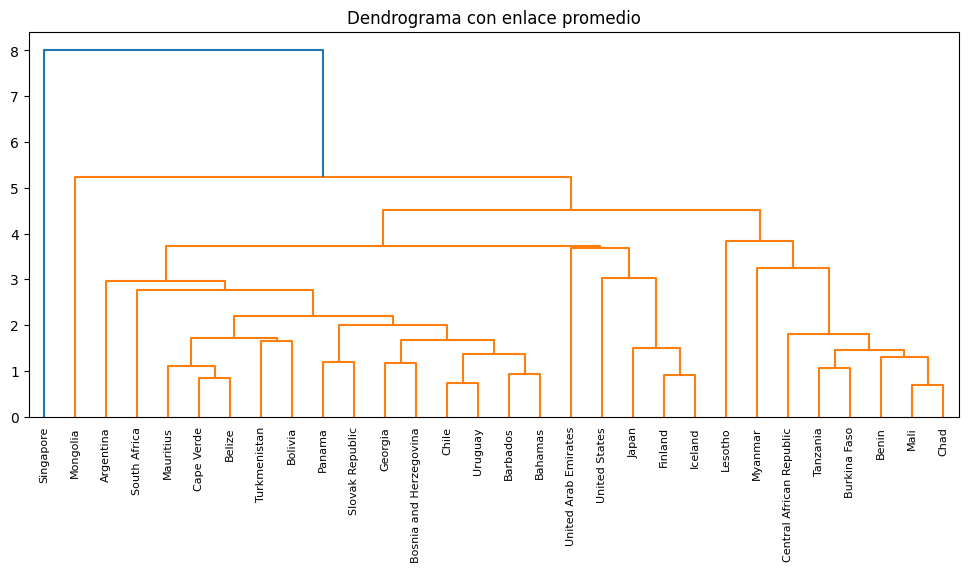

In [24]:
matriz_promedio = linkage(datos_estandarizados, method="average")

plt.figure(figsize=(12, 5))
dendrogram(
    matriz_promedio,
    labels=nombres_paises.tolist(),
    leaf_rotation=90,
    leaf_font_size=8
)
plt.title("Dendrograma con enlace promedio")
plt.show()

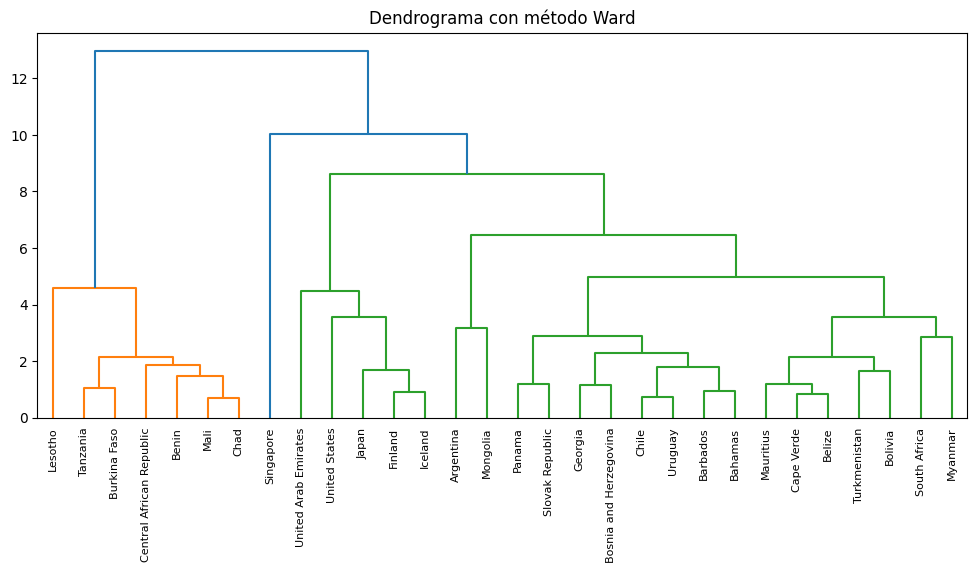

In [25]:
matriz_ward = linkage(datos_estandarizados, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(
    matriz_ward,
    labels=nombres_paises.tolist(),
    leaf_rotation=90,
    leaf_font_size=8
)
plt.title("Dendrograma con método Ward")
plt.show()

Comparación de los métodos: el enlace simple forma uniones como una cadena, el completo muestra separaciones más marcadas, el promedio queda en un punto intermedi, y Ward forma grupos más equilibrados. Elegiré Ward para continuar porque sus grupos se ven más fáciles de comparar. La estandarización es importante porque, sin ella, income y gdpp podrían influir más en las distancias por sus valores altos.

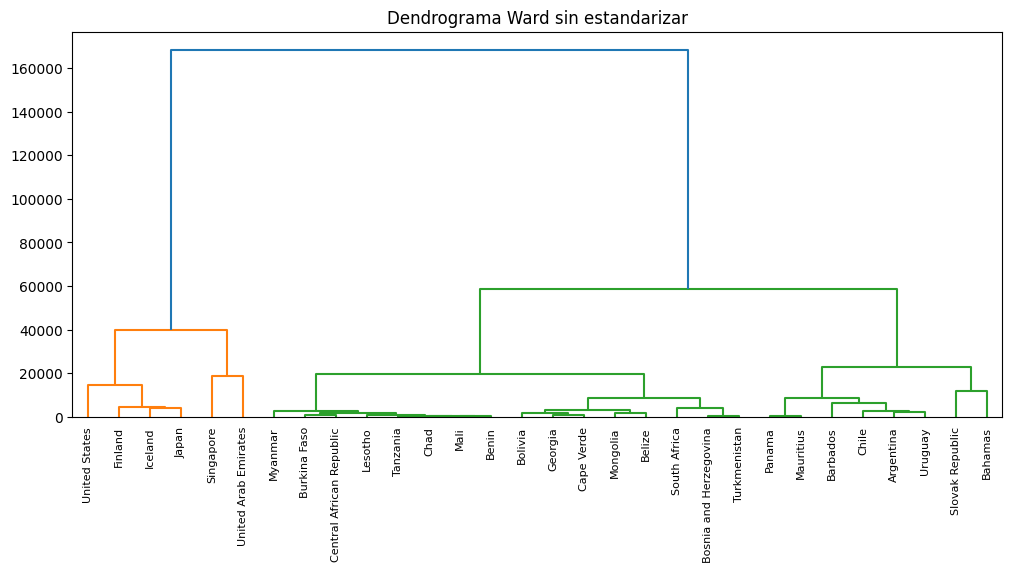

In [26]:
matriz_ward_original = linkage(datos_originales, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(
    matriz_ward_original,
    labels=nombres_paises.tolist(),
    leaf_rotation=90,
    leaf_font_size=8
)
plt.title("Dendrograma Ward sin estandarizar")
plt.show()

Efecto de no estandarizar: al usar los valores originales, las diferencias de ingreso y PIB por persona influyen mucho más en las agrupaciones. Por eso continuaré el análisis con los datos estandarizados, donde las variables pueden aportar de manera más equilibrada.

In [27]:
from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import silhouette_score

for cantidad in [2, 3, 4, 5]:
    grupos = fcluster(matriz_ward, t=cantidad, criterion="maxclust")
    silueta = silhouette_score(datos_estandarizados, grupos)
    print("Grupos:", cantidad, "| Silueta:", round(silueta, 3))

Grupos: 2 | Silueta: 0.329
Grupos: 3 | Silueta: 0.349
Grupos: 4 | Silueta: 0.312
Grupos: 5 | Silueta: 0.331


Cantidad de grupos elegida: elegiré 3 grupos. Probé entre 2 y 5, y la silueta más alta fue 0,349 con 3 grupos. La separación no es muy marcada, pero es la mejor de las opciones evaluadas. En el dendrograma de Ward, usaré un corte aproximado en la altura 9.

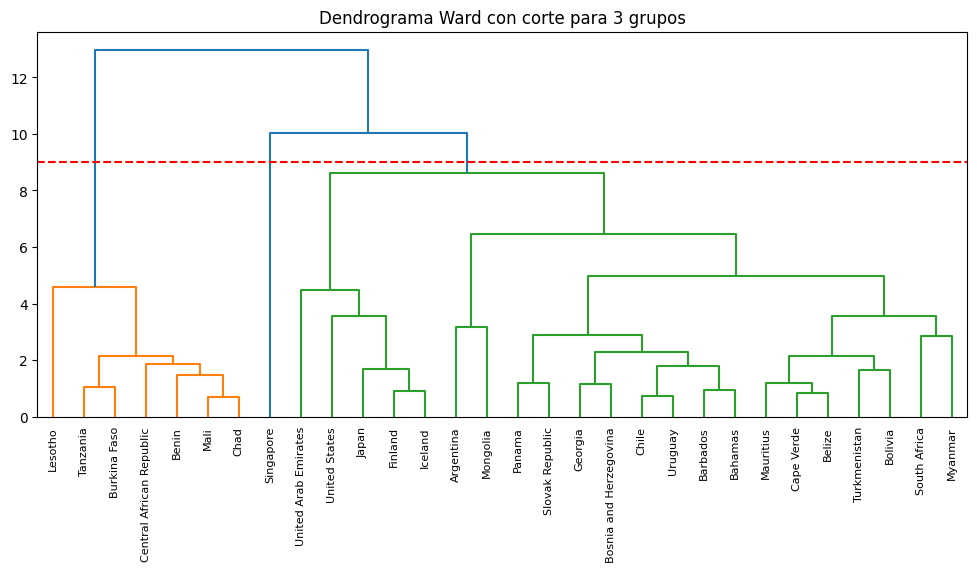

In [28]:
plt.figure(figsize=(12, 5))
dendrogram(
    matriz_ward,
    labels=nombres_paises.tolist(),
    leaf_rotation=90,
    leaf_font_size=8
)
plt.axhline(y=9, color="red", linestyle="--")
plt.title("Dendrograma Ward con corte para 3 grupos")
plt.show()

In [29]:
grupos_jerarquicos = fcluster(matriz_ward, t=3, criterion="maxclust")

resultado_paises = pd.DataFrame({
    "País": nombres_paises,
    "Grupo": grupos_jerarquicos
})

for grupo in [1, 2, 3]:
    print("Grupo", grupo)
    print(resultado_paises[resultado_paises["Grupo"] == grupo]["País"].tolist())
    print()

Grupo 1
['Mali', 'Tanzania', 'Lesotho', 'Burkina Faso', 'Central African Republic', 'Benin', 'Chad']

Grupo 2
['Argentina', 'Chile', 'Uruguay', 'South Africa', 'Panama', 'Georgia', 'Cape Verde', 'United States', 'Finland', 'Mongolia', 'Bosnia and Herzegovina', 'Belize', 'Iceland', 'Slovak Republic', 'Myanmar', 'Turkmenistan', 'Japan', 'Bolivia', 'Barbados', 'Bahamas', 'United Arab Emirates', 'Mauritius']

Grupo 3
['Singapore']



In [30]:
print("Países de cada grupo:")
for grupo in [1, 2, 3]:
    print("\nGrupo", grupo)
    paises_del_grupo = resultado_paises[resultado_paises["Grupo"] == grupo]["País"].tolist()
    print("\n".join(paises_del_grupo))

datos_perfil = datos_originales.copy()
datos_perfil["Grupo"] = grupos_jerarquicos

print("\nPromedio de las variables originales por grupo:")
print(datos_perfil.groupby("Grupo").mean().round(1))

Países de cada grupo:

Grupo 1
Mali
Tanzania
Lesotho
Burkina Faso
Central African Republic
Benin
Chad

Grupo 2
Argentina
Chile
Uruguay
South Africa
Panama
Georgia
Cape Verde
United States
Finland
Mongolia
Bosnia and Herzegovina
Belize
Iceland
Slovak Republic
Myanmar
Turkmenistan
Japan
Bolivia
Barbados
Bahamas
United Arab Emirates
Mauritius

Grupo 3
Singapore

Promedio de las variables originales por grupo:
       child_mort  exports  health  imports   income  inflation  life_expec  \
Grupo                                                                         
1           119.2     24.6     5.9     43.1   1772.6        4.8        55.6   
2            20.4     40.9     7.6     42.9  20010.9        6.0        74.0   
3             2.8    200.0     4.0    174.0  72100.0       -0.0        82.7   

       total_fer     gdpp  
Grupo                      
1            5.5    750.9  
2            2.1  16379.0  
3            1.2  46600.0  


Perfil de los grupos: el grupo 1 reúne países con menor ingreso y PIB por persona, mayor mortalidad infantil y menor esperanza de vida. El grupo 2 presenta valores intermedios e incluye a Chile, Argentina y Uruguay. El grupo 3 está compuesto solo por Singapur, que muestra ingresos y PIB por persona elevados. Estos perfiles resumen los promedios de la muestra analizada.

In [31]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

modelo_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
grupos_kmeans = modelo_kmeans.fit_predict(datos_estandarizados) + 1

print("Comparación entre Ward y K-Means:")
print(pd.crosstab(grupos_jerarquicos, grupos_kmeans))

print("\nCoincidencia entre métodos:")
print(round(adjusted_rand_score(grupos_jerarquicos, grupos_kmeans), 3))

Comparación entre Ward y K-Means:
col_0   1  2  3
row_0          
1       0  7  0
2      17  5  0
3       0  0  1

Coincidencia entre métodos:
0.454


### Comparación y conclusión

En el corte de Ward, Chile quedó en el grupo 2 junto con Argentina y Uruguay, respondiendo la pregunta guía.  
La tabla muestra que ese grupo se dividió en dos grupos de K-Means: 17 países quedaron en uno y 5 en otro.  
Los grupos 1 y 3 de Ward quedaron agrupados respectivamente con las etiquetas 2 y 3 de K-Means.  
El ARI de 0.454 refleja una coincidencia parcial entre ambos métodos.  
Presentaría Ward porque el dendrograma permite observar la jerarquía y justificar el corte elegido.  
La interpretación está limitada a la muestra de 30 países y a los indicadores seleccionados; estos grupos no demuestran relaciones de causa y efecto.